In [ ]:
import sklearn.datasets as ds
import sklearn.neural_network as nn
import matplotlib.pyplot as plt
import numpy as np

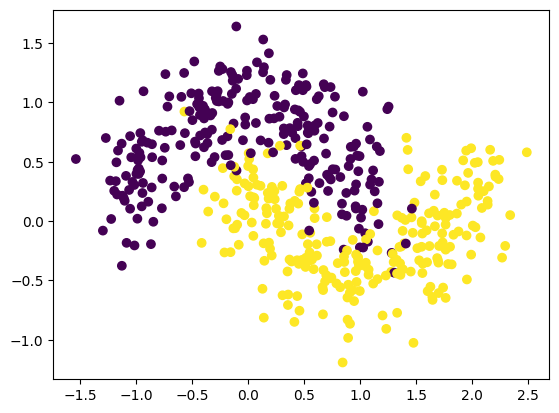

In [ ]:
x,y = ds.make_moons(n_samples=500,noise=0.25,random_state=33)
plt.scatter(x[:,0],x[:,1],c=y)
plt.show()

In [ ]:
def draw_area(x,y,model):
  # 1. 그래프의 x,y 축의 범위 설정
  x_min,x_max = x[:,0].min()-1, x[:,0].max()+1
  y_min,y_max = x[:,1].min()-1, x[:,1].max()+1

  # 2. 만든 범위를 0.01 간격으로 촘촘한 값을 생성
  pos_x = np.arange(x_min,x_max,0.01)
  pos_y = np.arange(y_min,y_max,0.01)
  # print(f'pos X : {pos_x}')
  # print(f'pos Y : {pos_y}')

  # 3. 격자 형태로 x,y 배열을 만든다.
  xx,yy = np.meshgrid(pos_x, pos_y)

  # 4. 두 배열을 합쳐서 일렬로 만들어 준다.
  # 두 배열을 합칠때 각각 1차원 이어야 하는데 xx, yy 는 2차원이다.
  # 그래서 ravel() 함수를 통해 1차원으로 만든다.
  val = np.c_[xx.ravel(),yy.ravel()]
  # print(val) # [[x,y],[x,y],...]

  # 5. 이렇게 생성된 값으로 모델에 예측을 시킨다.
  z = model.predict(val)
  print(z)

  # 6. 영역을 그려준다.
  plt.scatter(x[:,0],x[:,1], c=y)
  plt.contourf(xx,yy,z.reshape(xx.shape),alpha=0.3)
  plt.show()

[0 0 0 ... 1 1 1]


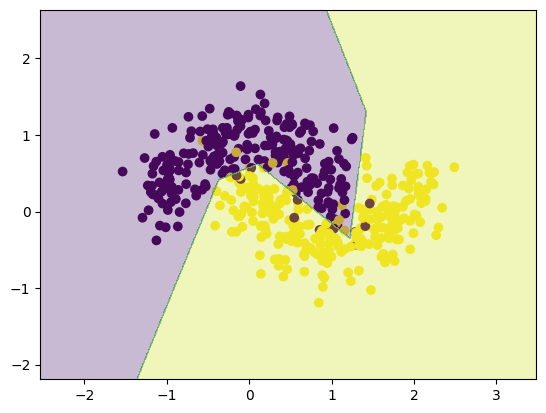

In [ ]:
#relu(기본값)-비선형 문제에 강점,빠르고 성능이 좋은편,음수 입력시 뉴런이 죽어 단순화될 가능성이 있음
model = nn.MLPClassifier(solver='lbfgs',max_iter=100000,hidden_layer_sizes=(10,),random_state=33).fit(x,y)
draw_area(x,y,model)

[1 1 1 ... 0 0 0]


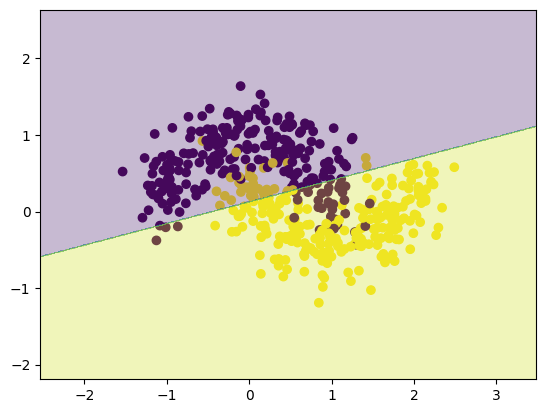

In [ ]:
#identity-비선형 문제 불가능
#속도가 빠르고 단순 계산에 특화되어 복잡한 패턴에 부적합,직선만 가능
model = nn.MLPClassifier(solver='lbfgs',max_iter=100000,hidden_layer_sizes=(10,),random_state=33,activation='identity').fit(x,y)
draw_area(x,y,model)

[0 0 0 ... 1 1 1]


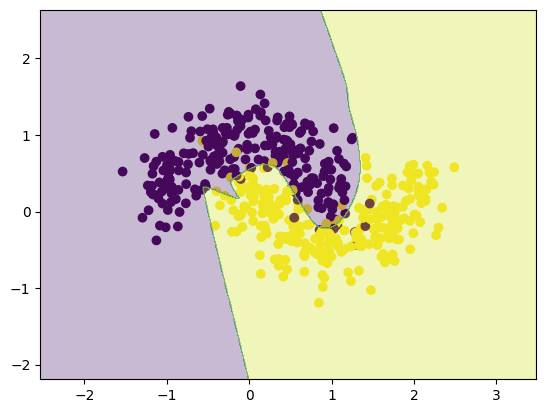

In [ ]:
#tanh-고전 신경망에서 쓰이던 방식,비선형 문제가 해결 가능,S자 곡선 가능
model = nn.MLPClassifier(solver='lbfgs',max_iter=100000,hidden_layer_sizes=(10,),random_state=33,activation='tanh').fit(x,y)
draw_area(x,y,model)

[0 0 0 ... 1 1 1]


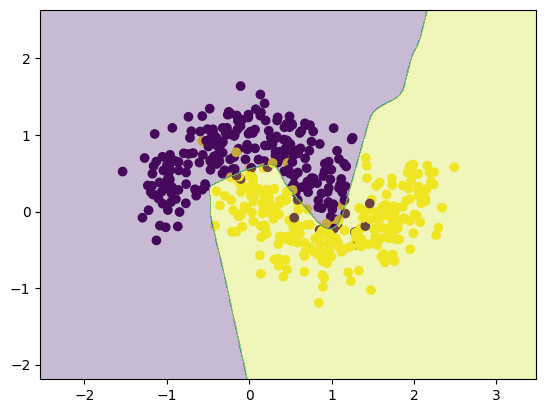

In [ ]:
#logistic-이진분류에 특화됨,비선형 문제가능,S자 곡선이 가능
model = nn.MLPClassifier(solver='lbfgs',max_iter=100000,hidden_layer_sizes=(10,),random_state=33,activation='logistic').fit(x,y)
draw_area(x,y,model)

[0 0 0 ... 1 1 1]


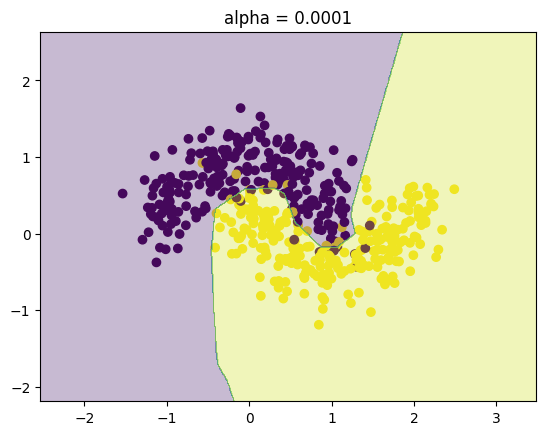

[0 0 0 ... 1 1 1]


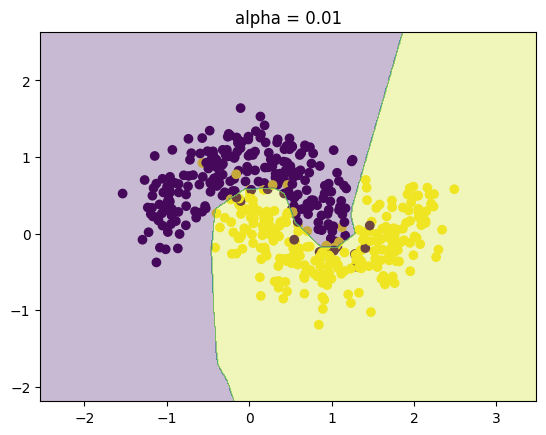

[0 0 0 ... 1 1 1]


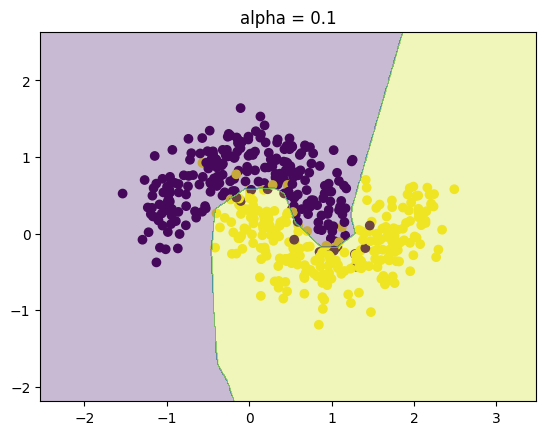

[0 0 0 ... 1 1 1]


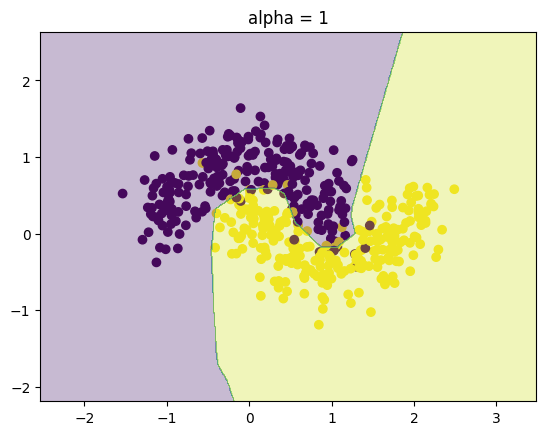

In [ ]:
#alpha=0.0001이 기본값,제약도(0.0001~1.0)
#[0.0001,0.01,0.1,1]
for a in [0.0001, 0.01, 0.1, 1]:
  model = nn.MLPClassifier(solver = 'lbfgs', max_iter=100000, hidden_layer_sizes=(50,50), random_state=33, alpha=0.0001)
  model.fit(x,y)
  plt.title(f'alpha = {a}')
  draw_area(x,y,model)